# Zadanie 1 — PenDigits

**Cel:** poznaj numeryczny zbiór danych, porównaj kilka uzasadnionych metod klasyfikacji statystycznej i uczenia maszynowego oraz oceń, czy większa złożoność modelu daje istotną korzyść.

In [1]:
# Proponowane importy — możesz je zmienić lub rozszerzyć.
from pathlib import Path
from zipfile import ZipFile

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from huggingface_hub import hf_hub_download
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.model_selection import cross_validate
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

In [2]:
# Pobranie niezmienionego archiwum z oficjalnymi podziałami train/test.
DATA_DIR = Path("data/zadanie-1")
DATA_DIR.mkdir(parents=True, exist_ok=True)

archive_path = hf_hub_download(
    repo_id="AI-MED-AGH/Recruitment-Task-1",
    filename="original/pen+based+recognition+of+handwritten+digits.zip",
    repo_type="dataset",
    local_dir=DATA_DIR,
)
with ZipFile(archive_path) as archive:
    archive.extractall(DATA_DIR / "pendigits")

print(f"Dane zapisano w: {DATA_DIR / 'pendigits'}")

original/pen+based+recognition+of+handwr(…): reconstructing file:   0%|          |  0.00B / 1.67MB            

original/pen+based+recognition+of+handwr(…): downloading bytes:           |  0.00B            

Dane zapisano w: data\zadanie-1\pendigits


## A — Poznanie i przygotowanie danych

Rozpoznaj zmienną docelową i cechy, sprawdź rozkład klas, braki, duplikaty oraz zakresy wartości. Pokaż krótką eksplorację danych i uzasadnij preprocessing. Zachowaj oficjalny podział danych; nie zastępuj go losowym podziałem.

In [15]:
columns = [f"feature_{i+1}" for i in range(16)] + ["target"]

train_path = DATA_DIR/"pendigits"/"pendigits.tra"
test_path = DATA_DIR/"pendigits"/"pendigits.tes"

df_train = pd.read_csv(train_path, header=None, names=columns)
df_test = pd.read_csv(test_path, header=None, names=columns)

print("Zbiór treningowy - info:")
print(df_train.info())
print("\nBraki danych w zbiorze treningowym:", df_train.isnull().sum().sum())
print("Zbiór testowy - rozmiar:", df_test.shape)

print(f"Liczba duplikatów w zbiorze treningowym: {df_train.duplicated().sum()}")
print(f"Liczba duplikatów w zbiorze testowym: {df_test.duplicated().sum()}")

df_train = df_train.drop_duplicates().reset_index(drop=True)

Zbiór treningowy - info:
<class 'pandas.DataFrame'>
RangeIndex: 7494 entries, 0 to 7493
Data columns (total 17 columns):
 #   Column      Non-Null Count  Dtype
---  ------      --------------  -----
 0   feature_1   7494 non-null   int64
 1   feature_2   7494 non-null   int64
 2   feature_3   7494 non-null   int64
 3   feature_4   7494 non-null   int64
 4   feature_5   7494 non-null   int64
 5   feature_6   7494 non-null   int64
 6   feature_7   7494 non-null   int64
 7   feature_8   7494 non-null   int64
 8   feature_9   7494 non-null   int64
 9   feature_10  7494 non-null   int64
 10  feature_11  7494 non-null   int64
 11  feature_12  7494 non-null   int64
 12  feature_13  7494 non-null   int64
 13  feature_14  7494 non-null   int64
 14  feature_15  7494 non-null   int64
 15  feature_16  7494 non-null   int64
 16  target      7494 non-null   int64
dtypes: int64(17)
memory usage: 995.4 KB
None

Braki danych w zbiorze treningowym: 0
Zbiór testowy - rozmiar: (3498, 17)
Liczba duplikatów

Rozkład klas

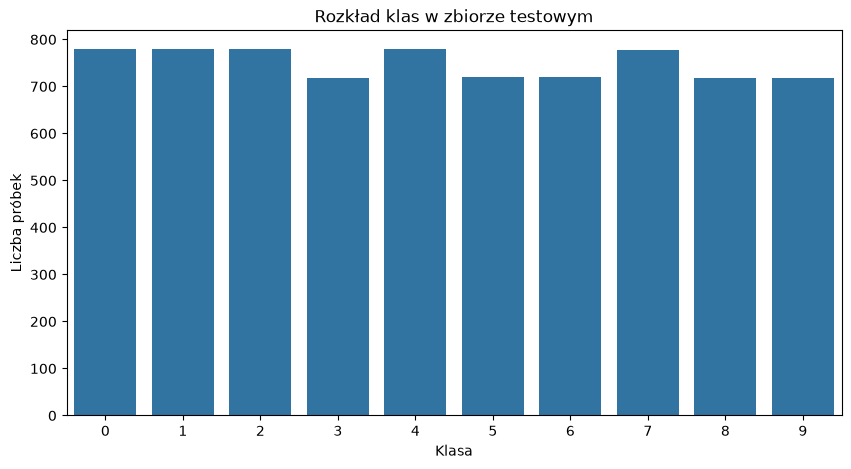

In [16]:
plt.figure(figsize=(10,5))
sns.countplot(data=df_train, x="target")
plt.title("Rozkład klas w zbiorze testowym")
plt.xlabel("Klasa")
plt.ylabel("Liczba próbek")
plt.show()

Sprawdzenie statystyk opisowych i podział danych

In [17]:
display(df_train.describe())

x_train = df_train.drop("target", axis=1)
y_train = df_train["target"]
x_test = df_test.drop("target", axis=1)
y_test = df_test["target"]

,feature_1,feature_2,feature_3,feature_4,feature_5,feature_6,feature_7,feature_8,feature_9,feature_10,feature_11,feature_12,feature_13,feature_14,feature_15,feature_16,target
count,7494.000000,7494.000000,7494.000000,7494.000000,7494.000000,7494.000000,7494.000000,7494.000000,7494.000000,7494.000000,7494.000000,7494.000000,7494.000000,7494.000000,7494.000000,7494.000000,7494.000000
mean,37.384307,84.679343,40.005604,82.889512,50.878303,65.044436,51.471844,44.599680,57.129971,34.069122,61.417401,35.782092,54.699760,35.800774,46.813718,28.565386,4.430878
std,33.322024,16.848420,26.256025,19.638582,34.927201,27.377341,30.680075,30.659478,33.680340,27.459989,37.130762,27.495836,22.599781,33.223611,41.531794,35.811094,2.876981
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,5.000000,76.000000,20.000000,70.000000,17.000000,48.000000,28.000000,22.000000,30.000000,7.000000,25.000000,12.000000,41.000000,7.000000,0.000000,0.000000,2.000000
50%,31.000000,89.000000,39.000000,89.000000,56.000000,71.000000,54.000000,42.000000,60.000000,33.000000,74.000000,32.000000,53.000000,28.000000,39.000000,8.000000,4.000000
75%,61.000000,100.000000,58.000000,100.000000,81.000000,86.000000,75.000000,65.000000,88.000000,55.000000,98.000000,57.000000,69.000000,48.000000,100.000000,51.000000,7.000000
max,100.000000,100.000000,100.000000,100.000000,100.000000,100.000000,100.000000,100.000000,100.000000,100.000000,100.000000,100.000000,100.000000,100.000000,100.000000,100.000000,9.000000


## B — Modelowanie

Zbuduj prosty model bazowy i porównaj go z kilkoma klasyfikatorami statystycznymi lub klasycznego uczenia maszynowego. Wykonaj dobór modeli, strojenie i sposób zapobiegania wyciekowi danych. 

## C — Porównanie i wnioski

Porównaj modele na oficjalnym zbiorze testowym za pomocą odpowiednich metryk liczbowych. Uwzględnij błędy oraz praktyczny koszt modeli, np. czas uczenia i inferencji albo liczbę parametrów. Odpowiedz, czy wzrost złożoności jest wart uzyskanej poprawy.

## Oddanie zadania

Zapisz kod, wyniki, wykresy i krótkie uzasadnienia w tym notatniku. Podaj użyte źródła oraz narzędzia AI i upewnij się, że notatnik można uruchomić od początku do końca. Wykonaj commit po zakończeniu zadania aby znalazł się na repozytorium.